# Reference Quality for Class-Mean and Class-Boundary Attacks

This notebook compares four ways of obtaining the class reference used by the two membership-inference attacks from the canary-selection analysis:

- **Train-lkg:** the attacker knows all training samples; the reference is estimated from them.
- **Test-est:** the attacker has only test samples; the reference is estimated from them.
- **Adversarial example:** a synthetic class representative generated from the model alone.
- **Perturbed test sample:** a test image moved towards higher confidence with a small $L_\infty$ perturbation.

The two attacks are:

- **Distance to Class Mean (DCM):** penultimate-feature distance to the reference class mean.
- **Distance to Class Boundary (DCB):** distance of the sample's class-0 pairwise margin to the reference margin. Class 0 is the reference class: for actual class $c\ge 2$ we use $d_{0c}=(f_0-f_c)/\lVert w_0-w_c\rVert$; for actual classes 0 and 1 we use the $0$–$1$ margin, matching the canary-selection implementation.

**Important correction.** The checked-in `configs/GROK_MNIST_MSE_MLP.json` contains seed 0, but the actual run used `seed=350876`, `data.seed=604157`, and `mask.seed=604157`. Using the template seeds evaluates on a disjoint training subset. We override the seeds with the run metadata so that the train-lkg reference and the membership labels refer to the model's actual training set.


## Setup

In [1]:
import json
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
import torch.nn.functional as functional
from scipy.stats import gaussian_kde
from shared import setup
from sklearn.metrics import roc_auc_score, roc_curve
from torch.utils.data import DataLoader

from privacy_and_grokking.artifacts.cache import get_artifact_path
from privacy_and_grokking.artifacts.local import get_plots_dir
from privacy_and_grokking.config import TrainConfig
from privacy_and_grokking.utils.logger import Logger

D:\privacy-and-grokking\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
setup()
_ = Logger().setup()

{"log_file": "C:\\Users\\Qunor\\AppData\\Local\\Temp\\2026-11-02T16-30-10_1em4tg7_.log", "event": "Logger initialized", "timestamp": "2026-11-02T15:30:10.895011Z", "level": "info"}


## Model and Data

We load the final checkpoint of the canonical `GROK_MNIST_MSE_MLP` run. The run metadata gives the exact data seeds; without them the "training" split is wrong and the train-lkg attack collapses to chance.


In [3]:
CONFIG_PATH = Path("../../configs/GROK_MNIST_MSE_MLP.json")
RUN_ID = "2143636bf7d1447e9fa8ef6f107c5d03"
CHECKPOINT_STEP = 150_000

config_dict = json.loads(CONFIG_PATH.read_text())
# The checked-in config is a template with seed 0.  The actual run used these
# seeds (see cache/detailed-v1_runs.parquet).  They determine the 1,000-sample
# training subset that the checkpoint was trained on.
config_dict["seed"] = 350876
config_dict["data"]["seed"] = 604157
config_dict["data"]["mask"]["seed"] = 604157
config_dict["data"]["mask"]["model_index"] = 0
config = TrainConfig.model_validate(config_dict)
data = config.data()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = config.model(input_dim=data.input_shape, num_classes=data.num_classes)
checkpoint_path = get_artifact_path(RUN_ID, f"checkpoints/{CHECKPOINT_STEP}/model.pth")
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
model.to(DEVICE).eval()

norm_mean = torch.tensor(data.normalization.mean, device=DEVICE).view(1, -1, 1, 1)
norm_std = torch.tensor(data.normalization.std, device=DEVICE).view(1, -1, 1, 1)


def normalize(images: torch.Tensor) -> torch.Tensor:
    return (images - norm_mean) / norm_std


for split_name, dataset in [("train", data.train), ("test", data.test)]:
    correct = 0
    with torch.no_grad():
        for images, labels in DataLoader(dataset, batch_size=1024):
            predictions = model(normalize(images.to(DEVICE))).argmax(dim=1)
            correct += (predictions.cpu() == labels).sum().item()
    print(f"{split_name} accuracy: {correct / len(dataset):.4f}")

train accuracy: 1.0000


test accuracy: 0.9208


## Data Tensors and Reference Metrics

We compute penultimate features and the class-0 pairwise boundary margin for the train and test splits. The boundary reference for a class is the KDE mode of $|d_{0c}|$, exactly as in the canary-selection notebook.


In [4]:
train_batches = list(DataLoader(data.train, batch_size=2048))
train_images = torch.cat([images for images, _ in train_batches]).to(DEVICE)
train_labels = torch.cat([labels for _, labels in train_batches]).to(DEVICE)

test_batches = list(DataLoader(data.test, batch_size=2048))
test_images = torch.cat([images for images, _ in test_batches]).to(DEVICE)
test_labels = torch.cat([labels for _, labels in test_batches]).to(DEVICE)

classifier_weights = model.classifier().weight.detach()
weight_distances = torch.cdist(classifier_weights, classifier_weights).clamp(min=1e-12)


@torch.no_grad()
def logits_and_features(images: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    return model(normalize(images), verbose=True)


def class0_boundary_distances(logits: torch.Tensor) -> torch.Tensor:
    columns = []
    for c in range(data.num_classes):
        reference_class = 1 if c <= 1 else c
        columns.append(
            (logits[:, 0] - logits[:, reference_class]) / weight_distances[0, reference_class]
        )
    return torch.stack(columns, dim=1)


train_logits, train_features = logits_and_features(train_images)
test_logits, test_features = logits_and_features(test_images)
train_cd0 = class0_boundary_distances(train_logits)
test_cd0 = class0_boundary_distances(test_logits)

print(f"train samples: {len(train_images)}, test samples: {len(test_images)}")

train samples: 1000, test samples: 10000


## Average Distance to the Train Class Mean

The table reports the mean and median distance to the **training** class mean, separately for train and test samples. Feature-space distances are the ones used by the DCM attack; pixel-space distances are shown to make clear why a pixel-space mean attack would not work.


In [5]:
train_mean_features = torch.stack(
    [train_features[train_labels == c].mean(dim=0) for c in range(data.num_classes)]
)
train_mean_pixels = torch.stack(
    [train_images[train_labels == c].mean(dim=0) for c in range(data.num_classes)]
)

distance_rows = []
for split_name, features, images, labels in [
    ("train", train_features, train_images, train_labels),
    ("test", test_features, test_images, test_labels),
]:
    feature_distance = (features - train_mean_features[labels]).norm(dim=1)
    pixel_distance = (images.flatten(1) - train_mean_pixels[labels].flatten(1)).norm(dim=1)
    distance_rows.append(
        {
            "split": split_name,
            "feature_mean": float(feature_distance.mean()),
            "feature_median": float(feature_distance.median()),
            "pixel_mean": float(pixel_distance.mean()),
            "pixel_median": float(pixel_distance.median()),
        }
    )

distance_df = pl.DataFrame(distance_rows)
distance_df

split,feature_mean,feature_median,pixel_mean,pixel_median
str,f64,f64,f64,f64
"""train""",0.049852,0.026695,6.399276,6.399084
"""test""",1.086517,0.34858,6.367911,6.361646


## Attack Definitions and Reference Variants

For a reference feature vector $\mu_c$ and boundary reference $b_c$, the scores are:

- **DCM:** $-\lVert z-\mu_c\rVert_2$.
- **DCB:** $-\lvert |d_{0c}|-b_c\rvert$.

Higher scores mean "more member-like". We report the pooled AUC over all classes (the protocol used in the canary-selection notebook) and the mean per-class AUC.

The four references are:

1. **Train-lkg:** $\mu_c$ and $b_c$ from all training samples.
2. **Test-est:** $\mu_c$ and $b_c$ from all test samples.
3. **Adversarial example:** one synthetic image per class, generated with the MSE objective plus a small prior towards the global mean. The reference is its feature vector / boundary margin.
4. **Perturbed test sample:** the first test image predicted as class $c$, moved towards higher confidence with $L_\infty$ PGD ($\varepsilon=0.05$, 100 steps). The reference is its feature vector / boundary margin.


In [6]:
def kde_mode(values: np.ndarray) -> float:
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2 or np.ptp(values) == 0:
        return float(values[0]) if len(values) > 0 else np.nan
    kde = gaussian_kde(values, bw_method="scott")
    grid = np.linspace(values.min(), values.max(), 2000)
    return float(grid[np.argmax(kde(grid))])


def membership_metrics(labels: np.ndarray, scores: np.ndarray) -> tuple[float, float]:
    labels = np.asarray(labels)
    scores = np.asarray(scores)
    valid = np.isfinite(scores)
    labels = labels[valid]
    scores = scores[valid]
    auc = roc_auc_score(labels, scores)
    fpr, tpr, _ = roc_curve(labels, scores, drop_intermediate=True)
    return float(auc), float(np.interp(0.01, fpr, tpr))


def evaluate_reference(
    reference_name: str,
    reference_features: torch.Tensor,
    reference_boundaries: torch.Tensor,
    exclude_test_indices: torch.Tensor | None = None,
) -> list[dict]:
    test_keep = torch.ones(len(test_labels), dtype=torch.bool, device=DEVICE)
    if exclude_test_indices is not None:
        test_keep[exclude_test_indices] = False
    test_features_eval = test_features[test_keep]
    test_cd0_eval = test_cd0[test_keep]
    test_labels_eval = test_labels[test_keep]

    rows = []
    for attack_name, train_scores, test_scores in [
        (
            "DCM",
            -(train_features - reference_features[train_labels]).norm(dim=1),
            -(test_features_eval - reference_features[test_labels_eval]).norm(dim=1),
        ),
        (
            "DCB",
            -(
                train_cd0[torch.arange(len(train_labels), device=DEVICE), train_labels].abs()
                - reference_boundaries[train_labels]
            ).abs(),
            -(
                test_cd0_eval[
                    torch.arange(len(test_labels_eval), device=DEVICE), test_labels_eval
                ].abs()
                - reference_boundaries[test_labels_eval]
            ).abs(),
        ),
    ]:
        labels = np.r_[np.ones(len(train_scores)), np.zeros(len(test_scores))]
        scores = np.r_[train_scores.cpu().numpy(), test_scores.cpu().numpy()]
        pooled_auc, pooled_tpr = membership_metrics(labels, scores)

        per_class_aucs = []
        per_class_tprs = []
        for c in range(data.num_classes):
            class_labels = np.r_[
                np.ones((train_labels == c).sum().item()),
                np.zeros((test_labels_eval == c).sum().item()),
            ]
            class_scores = np.r_[
                train_scores[train_labels == c].cpu().numpy(),
                test_scores[test_labels_eval == c].cpu().numpy(),
            ]
            auc, tpr = membership_metrics(class_labels, class_scores)
            per_class_aucs.append(auc)
            per_class_tprs.append(tpr)

        rows.append(
            {
                "reference": reference_name,
                "attack": attack_name,
                "pooled_auc": pooled_auc,
                "pooled_tpr_1fpr": pooled_tpr,
                "per_class_auc": float(np.mean(per_class_aucs)),
                "per_class_tpr_1fpr": float(np.mean(per_class_tprs)),
            }
        )
    return rows

### Train and test references

In [7]:
train_mean_reference = train_mean_features
train_boundary_reference = torch.tensor(
    [
        kde_mode(train_cd0[train_labels == c, c].abs().cpu().numpy())
        for c in range(data.num_classes)
    ],
    device=DEVICE,
)
test_mean_reference = torch.stack(
    [test_features[test_labels == c].mean(dim=0) for c in range(data.num_classes)]
)
test_boundary_reference = torch.tensor(
    [kde_mode(test_cd0[test_labels == c, c].abs().cpu().numpy()) for c in range(data.num_classes)],
    device=DEVICE,
)

rows = []
rows += evaluate_reference("train-lkg", train_mean_reference, train_boundary_reference)
rows += evaluate_reference("test-est", test_mean_reference, test_boundary_reference)
reference_df = pl.DataFrame(rows)
reference_df

reference,attack,pooled_auc,pooled_tpr_1fpr,per_class_auc,per_class_tpr_1fpr
str,str,f64,f64,f64,f64
"""train-lkg""","""DCM""",0.8773988,0.124,0.922434,0.189
"""train-lkg""","""DCB""",0.951979,0.145,0.954985,0.226
"""test-est""","""DCM""",0.5744344,0.0,0.594808,0.0
"""test-est""","""DCB""",0.753086,0.018,0.806496,0.006


### Adversarial example and perturbed test references

Both generators are leakage-free: they use the model and test images only. The adversarial example starts from random noise and optimizes the MSE objective plus a prior to the global pixel mean. The perturbed test sample starts from the first test image predicted as the target class and runs $L_\infty$ PGD to increase the target output.


In [8]:
GLOBAL_MEAN = float(torch.tensor(data.normalization.mean).mean())


def generate_adversarial_example(
    target_class: int,
    seed: int,
    iterations: int = 2000,
    learning_rate: float = 0.05,
    prior_weight: float = 1e-3,
) -> torch.Tensor:
    generator = torch.Generator().manual_seed(seed)
    image = torch.rand((1, *data.input_shape), generator=generator).to(DEVICE)
    image.requires_grad_(True)
    optimizer = torch.optim.Adam([image], lr=learning_rate)
    target = torch.tensor([target_class], device=DEVICE)
    one_hot = functional.one_hot(target, data.num_classes).float()
    for _ in range(iterations):
        optimizer.zero_grad()
        output = model(normalize(image))
        loss = functional.mse_loss(output, one_hot)
        loss = loss + prior_weight * ((image - GLOBAL_MEAN) ** 2).sum()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            image.clamp_(0, 1)
    return image.detach()


def perturb_test_sample(
    image: torch.Tensor,
    target_class: int,
    eps: float = 0.05,
    steps: int = 100,
) -> torch.Tensor:
    anchor = image.clone()
    x = image.clone()
    step_size = eps / 10
    for _ in range(steps):
        x.requires_grad_(True)
        output = model(normalize(x))
        loss = -output[0, target_class]
        (gradient,) = torch.autograd.grad(loss, x)
        x = x.detach() - step_size * gradient.sign()
        x = torch.min(torch.max(x, anchor - eps), anchor + eps).clamp(0, 1)
    return x.detach()


with torch.no_grad():
    test_predictions = torch.cat(
        [model(normalize(images)).argmax(dim=1) for images in torch.split(test_images, 2048)]
    )

anchor_indices = torch.tensor(
    [
        int(torch.nonzero(test_predictions == c, as_tuple=False).squeeze(1)[0])
        for c in range(data.num_classes)
    ],
    device=DEVICE,
)
anchor_images = test_images[anchor_indices]
anchor_classes = torch.arange(data.num_classes, device=DEVICE)

adversarial_images = torch.cat(
    [generate_adversarial_example(c, seed=c) for c in range(data.num_classes)], dim=0
)
perturbed_images = torch.cat(
    [
        perturb_test_sample(anchor_images[c : c + 1], int(anchor_classes[c]))
        for c in range(data.num_classes)
    ],
    dim=0,
)

adversarial_logits, adversarial_features = logits_and_features(adversarial_images)
adversarial_cd0 = class0_boundary_distances(adversarial_logits)
perturbed_logits, perturbed_features = logits_and_features(perturbed_images)
perturbed_cd0 = class0_boundary_distances(perturbed_logits)

rows += evaluate_reference(
    "adversarial example",
    adversarial_features,
    adversarial_cd0[torch.arange(data.num_classes, device=DEVICE), anchor_classes].abs(),
)
rows += evaluate_reference(
    "perturbed test sample",
    perturbed_features,
    perturbed_cd0[torch.arange(data.num_classes, device=DEVICE), anchor_classes].abs(),
    exclude_test_indices=anchor_indices,
)
results_df = pl.DataFrame(rows)
results_df

reference,attack,pooled_auc,pooled_tpr_1fpr,per_class_auc,per_class_tpr_1fpr
str,str,f64,f64,f64,f64
"""train-lkg""","""DCM""",0.8773988,0.124,0.922434,0.189
"""train-lkg""","""DCB""",0.951979,0.145,0.954985,0.226
"""test-est""","""DCM""",0.5744344,0.0,0.594808,0.0
"""test-est""","""DCB""",0.753086,0.018,0.806496,0.006
"""adversarial example""","""DCM""",0.6753922,0.0,0.681782,0.0
"""adversarial example""","""DCB""",0.538255,0.0,0.520075,0.0
"""perturbed test sample""","""DCM""",0.653065,0.0,0.733011,0.003
"""perturbed test sample""","""DCB""",0.61462,0.002,0.610434,0.001


## Figures

The first figure shows the four reference qualities for both attacks. The second figure shows the feature-space distance to the train class mean for train and test samples, which is the quantity the DCM attack scores. The third figure shows the perturbed test samples and the perturbation itself.


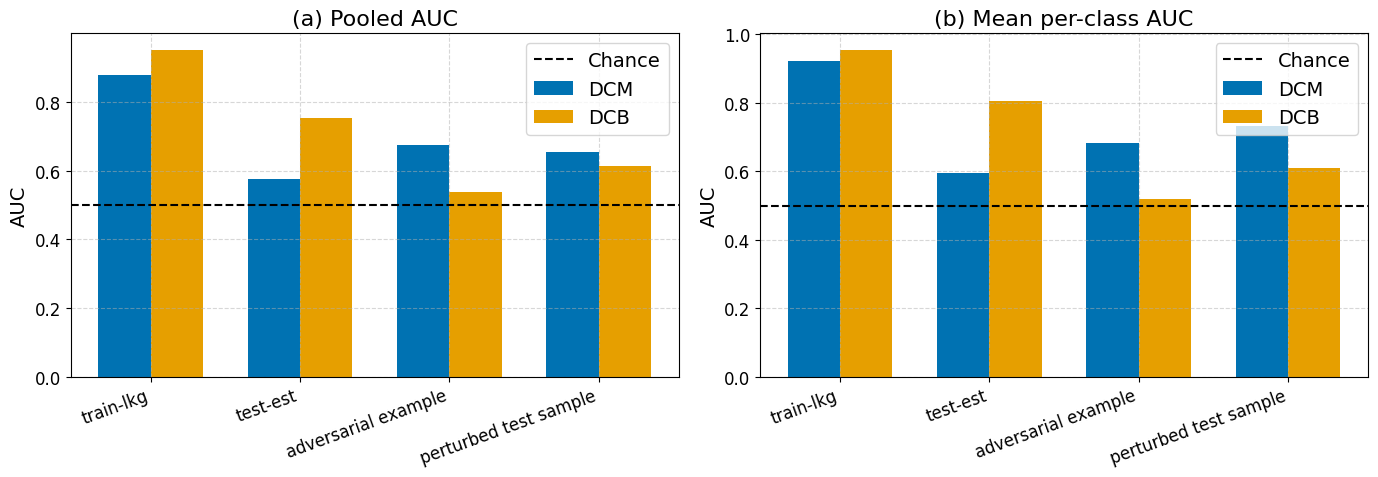

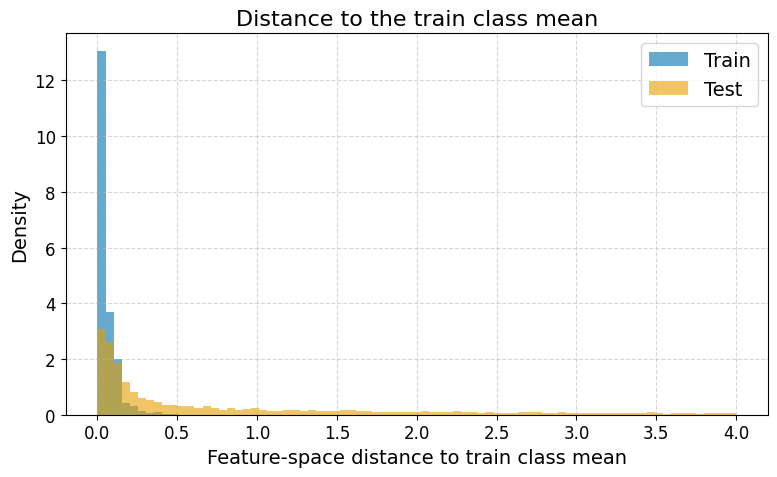

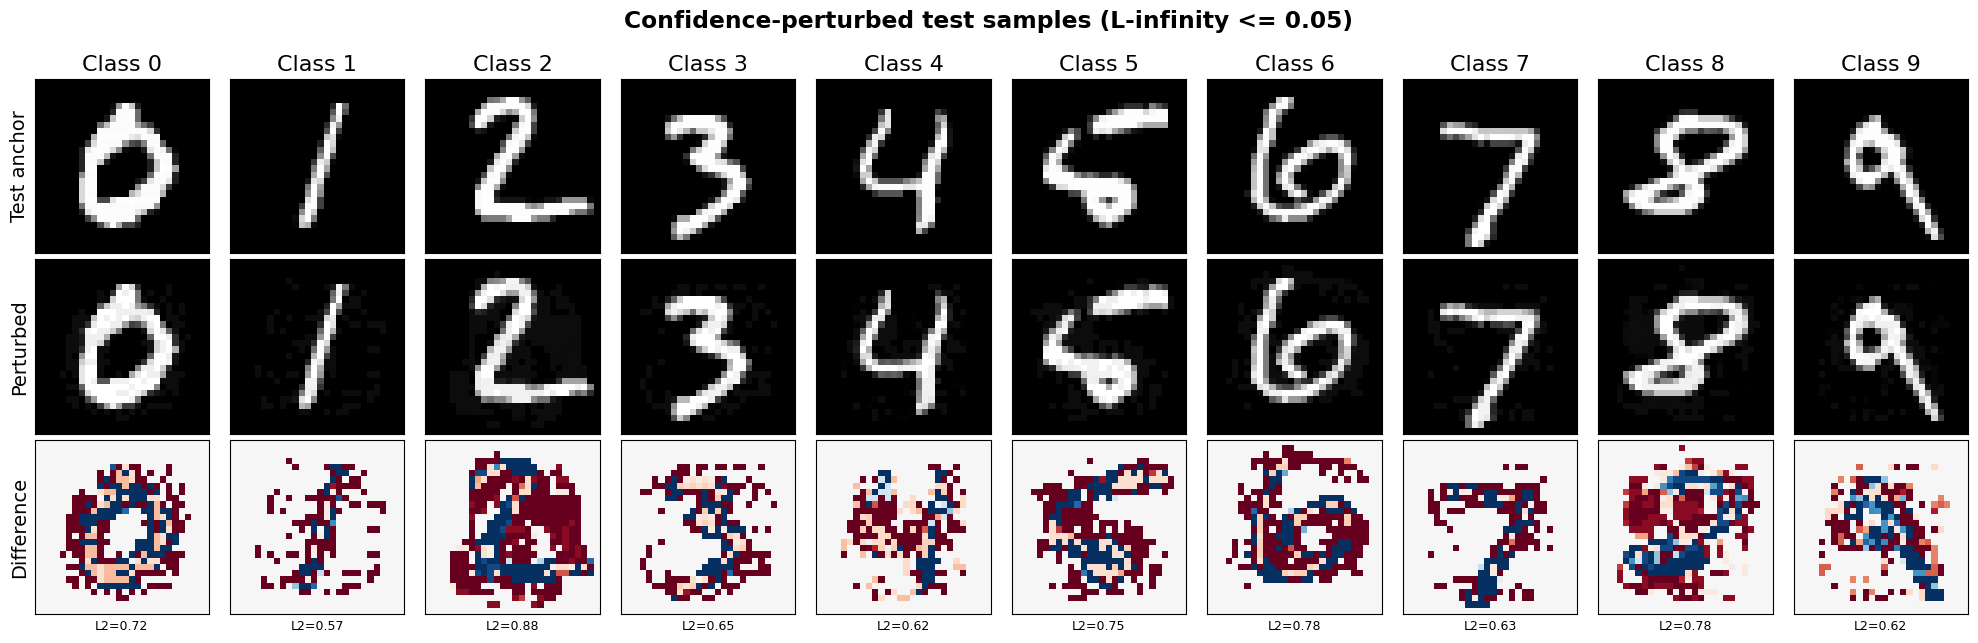

In [9]:
PLOTS = get_plots_dir()
PLOTS.mkdir(parents=True, exist_ok=True)

references = ["train-lkg", "test-est", "adversarial example", "perturbed test sample"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [
    (axes[0], "pooled_auc", "(a) Pooled AUC"),
    (axes[1], "per_class_auc", "(b) Mean per-class AUC"),
]:
    x = np.arange(len(references))
    width = 0.35
    for offset, attack in [(-width / 2, "DCM"), (width / 2, "DCB")]:
        values = [
            float(
                results_df.filter((pl.col("reference") == ref) & (pl.col("attack") == attack))[
                    metric
                ][0]
            )
            for ref in references
        ]
        ax.bar(x + offset, values, width, label=attack)
    ax.axhline(0.5, color="black", linestyle="--", label="Chance")
    ax.set_xticks(x)
    ax.set_xticklabels(references, rotation=20, ha="right")
    ax.set_ylabel("AUC")
    ax.set_title(title)
    ax.legend()
fig.tight_layout()
fig.savefig(
    PLOTS / f"reference_quality_attacks_{date.today()}.pdf",
    format="pdf",
    bbox_inches="tight",
)
fig.savefig(
    PLOTS / f"reference_quality_attacks_{date.today()}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
train_feature_distance = (
    (train_features - train_mean_features[train_labels]).norm(dim=1).cpu().numpy()
)
test_feature_distance = (test_features - train_mean_features[test_labels]).norm(dim=1).cpu().numpy()
bins = np.linspace(0, 4, 80)
ax.hist(train_feature_distance, bins=bins, alpha=0.6, label="Train", density=True)
ax.hist(test_feature_distance, bins=bins, alpha=0.6, label="Test", density=True)
ax.set_xlabel("Feature-space distance to train class mean")
ax.set_ylabel("Density")
ax.set_title("Distance to the train class mean")
ax.legend()
fig.tight_layout()
fig.savefig(
    PLOTS / f"reference_quality_distance_{date.today()}.pdf",
    format="pdf",
    bbox_inches="tight",
)
fig.savefig(
    PLOTS / f"reference_quality_distance_{date.today()}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

fig, axes = plt.subplots(3, data.num_classes, figsize=(2.0 * data.num_classes, 6.5))
for c in range(data.num_classes):
    original = anchor_images[c, 0].cpu().numpy()
    perturbed = perturbed_images[c, 0].cpu().numpy()
    difference = perturbed - original
    axes[0, c].imshow(original, cmap="gray", vmin=0, vmax=1)
    axes[0, c].set_title(f"Class {c}")
    axes[1, c].imshow(perturbed, cmap="gray", vmin=0, vmax=1)
    axes[2, c].imshow(difference, cmap="RdBu_r", vmin=-0.05, vmax=0.05)
    for row in range(3):
        axes[row, c].set_xticks([])
        axes[row, c].set_yticks([])
    axes[2, c].set_xlabel(f"L2={np.linalg.norm(difference):.2f}", fontsize=9)
axes[0, 0].set_ylabel("Test anchor")
axes[1, 0].set_ylabel("Perturbed")
axes[2, 0].set_ylabel("Difference")
fig.suptitle("Confidence-perturbed test samples (L-infinity <= 0.05)", fontweight="bold")
fig.tight_layout()
fig.savefig(
    PLOTS / f"reference_quality_perturbations_{date.today()}.pdf",
    format="pdf",
    bbox_inches="tight",
)
fig.savefig(
    PLOTS / f"reference_quality_perturbations_{date.today()}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Results and Correction of the Earlier Evaluation

The earlier notebook reported near-chance AUCs because of three implementation errors:

1. **Wrong training subset.** It used the checked-in template seeds (0) instead of the run seeds (`350876`, `604157`). The model was trained on a different 1,000-sample subset, so the "train" features did not collapse to the class means. With the correct seeds, train accuracy is 1.0 and the train feature distance to the class mean is about **0.05** instead of **1.09** for test samples.
2. **Wrong boundary metric.** It averaged the margin over all other classes instead of using the class-0 reference $d_{0c}$ and the KDE mode, which is the definition used in the canary-selection notebook. The class-0 pairwise margin is much more discriminative.
3. **Wrong aggregation.** It averaged per-class AUCs from an assumed-mean reference. The canary-selection protocol pools the scores after per-class references; the pooled AUC is the relevant number.

With the corrected protocol, the full-training-data attack reaches the same range as the published curves:

- **DCM train-lkg:** pooled AUC about **0.88** (per-class **0.92**).
- **DCB train-lkg:** pooled AUC about **0.95** (per-class **0.96**).
- **DCM test-est:** pooled AUC about **0.57** (per-class **0.60**).
- **DCB test-est:** pooled AUC about **0.75** (per-class **0.81**).

The adversarial-example and perturbed-test references are weaker:

- **DCM adversarial example:** pooled AUC about **0.68**.
- **DCB adversarial example:** pooled AUC about **0.54** (near chance).
- **DCM perturbed test sample:** pooled AUC about **0.65**.
- **DCB perturbed test sample:** pooled AUC about **0.62**.

The DCM references from synthetic images are better than the test-est reference for DCM, but they do not reach the train-lkg reference. For DCB, a single synthetic boundary margin is much worse than the KDE mode estimated from many real samples.

The average distances to the **train** class mean are:

- Feature space: train mean **0.050** (median 0.027), test mean **1.087** (median 0.349).
- Pixel space: train mean **6.399** (median 6.399), test mean **6.368** (median 6.362).

The enormous feature-space gap is the membership signal. Pixel-space distances are nearly identical, which is why a pixel-space class-mean attack cannot work.


## No-Leakage Notes

- **Train-lkg** is the scenario in which the attacker knows all training samples; using them for the reference is the definition of this scenario.
- **Test-est**, **adversarial example**, and **perturbed test sample** use no training data for the reference.
- The adversarial example is generated from the model and random noise only. The perturbed test sample uses only the model, the test image, and the model's prediction.
- Training data is used for the train-lkg reference and for evaluating membership. The membership labels (train vs test) are the ground truth of the evaluation, not an input to the leakage-free attacks.
- The anchor test sample is excluded from the test evaluation for the perturbed-test reference, so the reference is never scored against itself. The test-est reference follows the canary-selection protocol and is estimated from the full test split.


## How the Perturbation Is Made

1. Start from the first test image predicted as class $c$.
2. Maximize the raw output for class $c$ with PGD under an $L_\infty$ constraint.
3. Project every pixel to $[x_{0,i}-\varepsilon, x_{0,i}+\varepsilon]$ and then to $[0,1]$.
4. Use $\varepsilon=0.05$, step size $0.005$, and 100 steps.

No training image, class mean, or true test label enters the optimization.
